# 01 · Exploration des données

Premier contact avec les deux sources du projet :

- **Sen1Floods11** : inondations, Sentinel-2 niveau **L1C** (13 bandes)
- **CaBuAr** : zones brûlées en Californie, Sentinel-2 niveau **L2A** (12 bandes)

Objectifs :

1. Voir à quoi ressemblent les images dans différentes compositions de bandes.
2. Vérifier que les indices **NDWI** (eau) et **NBR** (brûlé) font ressortir les anomalies.
3. Mesurer combien de tuiles seraient en alerte selon le seuil choisi.
4. Constater la différence entre L1C et L2A.

Aucun entraînement ici. Les données viennent de `scripts/download_samples.py` :

```bash
uv run python scripts/download_samples.py
```

In [ ]:
%config InlineBackend.figure_formats = ["jpeg"]
import json
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from rasterio.errors import NotGeoreferencedWarning

from onelook.data import sources
from onelook.data.sentinel2 import (
    false_color_infrared, false_color_swir, get_bands, natural_color, nbr, ndwi,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
S1F = RAW / "sen1floods11"
CAB = RAW / "cabuar"
warnings.filterwarnings("ignore", category=NotGeoreferencedWarning)  # tuiles CaBuAr sans géoréférence

# Couleurs du Design System One Look
INK, MUTED, LINE = "#14202b", "#4f5f6b", "#cfd8db"
BRAND, ALERT, NORMAL = "#1d5f96", "#a3470a", "#2b7253"
plt.rcParams.update({
    "figure.dpi": 90, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.edgecolor": LINE, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
})

def show_row(images, titles, cmaps=None, vranges=None, suptitle=None):
    fig, axes = plt.subplots(1, len(images), figsize=(3.2 * len(images), 3.4))
    for i, (ax, img, title) in enumerate(zip(axes, images, titles)):
        cmap = cmaps[i] if cmaps else None
        vmin, vmax = vranges[i] if vranges and vranges[i] else (None, None)
        im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
        ax.set_title(title); ax.axis("off")
        if cmap and img.ndim == 2 and cmap not in (MASK_CMAP, BURN_CMAP):
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    if suptitle:
        fig.suptitle(suptitle, x=0.01, ha="left", fontsize=11)
    fig.tight_layout()
    plt.show()

# Masque d'inondation : sans donnée, sec, eau permanente, inondation
MASK_CMAP = ListedColormap(["#9aa5ad", "#e6ebea", BRAND, ALERT])
BURN_CMAP = ListedColormap(["#e6ebea", ALERT])

def flood_mask_classes(label, permanent):
    out = np.ones_like(label, dtype=np.uint8)          # 1 = sec
    out[label == sources.LABEL_NODATA] = 0               # 0 = sans donnée (nuage, hors image)
    water = label == sources.LABEL_WATER
    out[water & (permanent > 0)] = 2                     # 2 = eau permanente
    out[water & (permanent == 0)] = 3                    # 3 = inondation
    return out

## 1. Sen1Floods11 : combien de tuiles inondées ?

Pour chaque tuile, on calcule la **part d'eau d'inondation** parmi les pixels visibles :
l'eau annotée, moins l'eau permanente (rivières, lacs) de la couche JRC.

446 tuiles, 11 pays
Tuiles par pays : {'Bolivia': 15, 'Ghana': 53, 'India': 68, 'Mekong': 30, 'Nigeria': 18, 'Pakistan': 28, 'Paraguay': 67, 'Somalia': 26, 'Spain': 30, 'Sri-Lanka': 42, 'USA': 69}
Part moyenne de pixels visibles : 86%


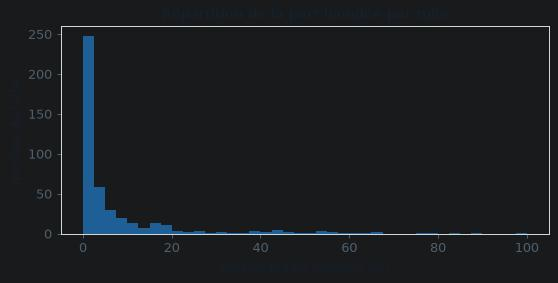

In [5]:
stats = json.loads((S1F / "stats.json").read_text())
flood = np.array([s["flood"] for s in stats.values()])
valid = np.array([s["valid"] for s in stats.values()])
countries = Counter(s["country"] for s in stats.values())

print(f"{len(stats)} tuiles, {len(countries)} pays")
print("Tuiles par pays :", dict(sorted(countries.items())))
print(f"Part moyenne de pixels visibles : {valid.mean():.0%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(flood * 100, bins=40, color=BRAND)
ax.set_xlabel("Part de pixels inondés (%)"); ax.set_ylabel("Nombre de tuiles")
ax.set_title("Répartition de la part inondée par tuile")
plt.show()

### Combien d'alertes selon le seuil ?

Le seuil décide à partir de quelle part inondée une image mérite une alerte.
C'est la question 1 du sujet : « définir ce qui mérite une alerte ».

In [6]:
print(f"{'Seuil':>6} | {'ALERTE':>6} | {'NORMAL':>6} | part d'alertes")
for threshold in [0.01, 0.02, 0.05, 0.10, 0.20]:
    n_alert = int((flood > threshold).sum())
    print(f"{threshold:>6.0%} | {n_alert:>6} | {len(flood) - n_alert:>6} | {n_alert / len(flood):.0%}")

 Seuil | ALERTE | NORMAL | part d'alertes
    1% |    273 |    173 | 61%
    2% |    216 |    230 | 48%
    5% |    139 |    307 | 31%
   10% |     89 |    357 | 20%
   20% |     43 |    403 | 10%


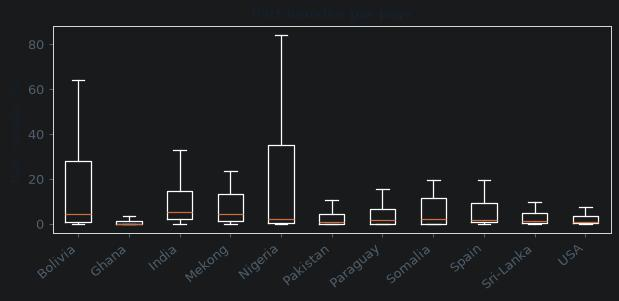

In [7]:
by_country = {}
for s in stats.values():
    by_country.setdefault(s["country"], []).append(s["flood"])
names = sorted(by_country)
fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot([np.array(by_country[n]) * 100 for n in names], tick_labels=names, showfliers=False)
ax.set_ylabel("Part inondée (%)"); ax.set_title("Part inondée par pays")
plt.xticks(rotation=40, ha="right"); plt.show()

## 2. Sen1Floods11 : à quoi ressemble une inondation ?

Pour chaque tuile échantillon :

- **Couleurs naturelles** (B04, B03, B02) : ce que verrait l'œil.
- **Infrarouge** (B08, B04, B03) : la végétation ressort en rouge vif. L'eau ne renvoie pas d'infrarouge et perd tout son rouge : noire si elle est claire, bleu-cyan si elle est boueuse.
- **SWIR** (B12, B08, B04) : l'eau apparaît bleu foncé, la végétation verte, le sol nu rose-violet.
- **NDWI** : positif (bleu) sur l'eau.
- **Masque annoté** : gris = sans donnée, clair = sec, bleu = eau permanente, orange = **inondation**.

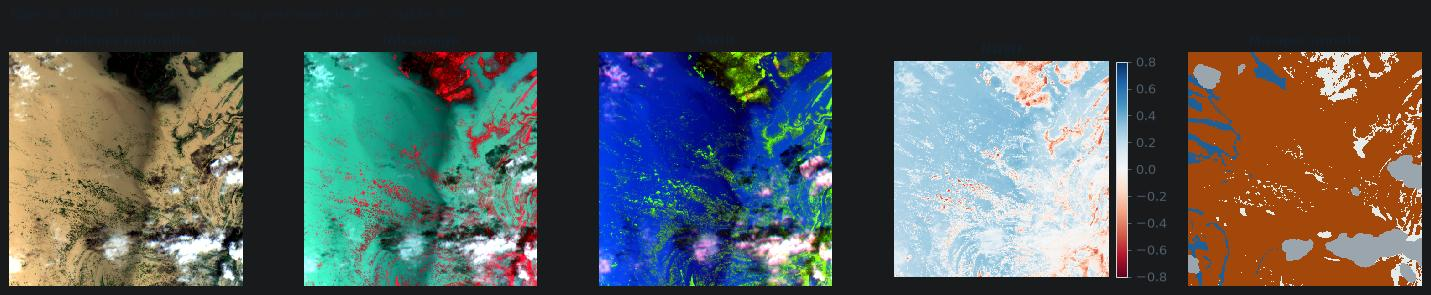

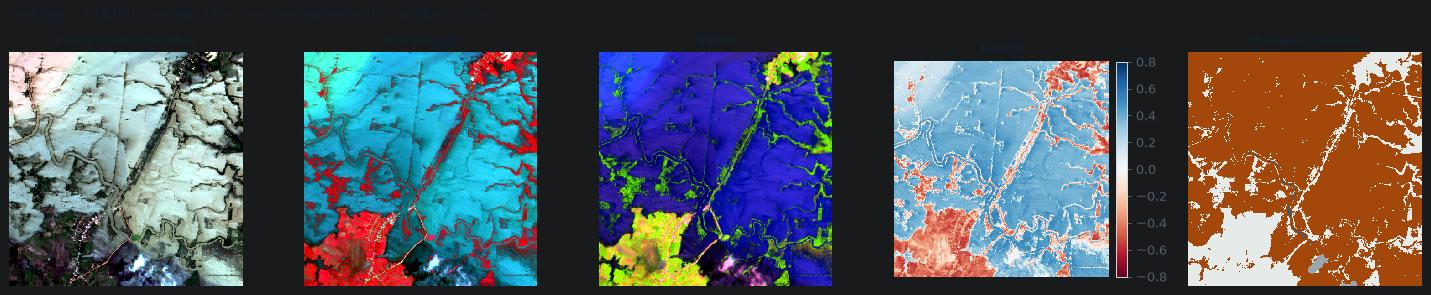

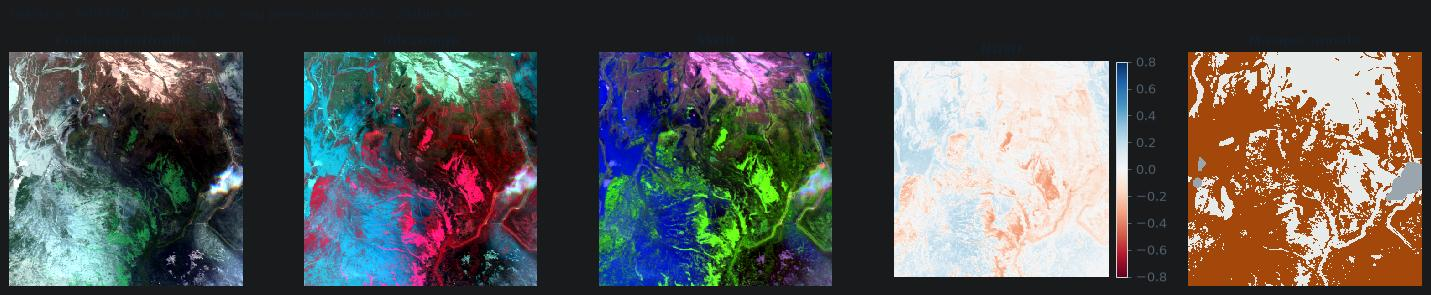

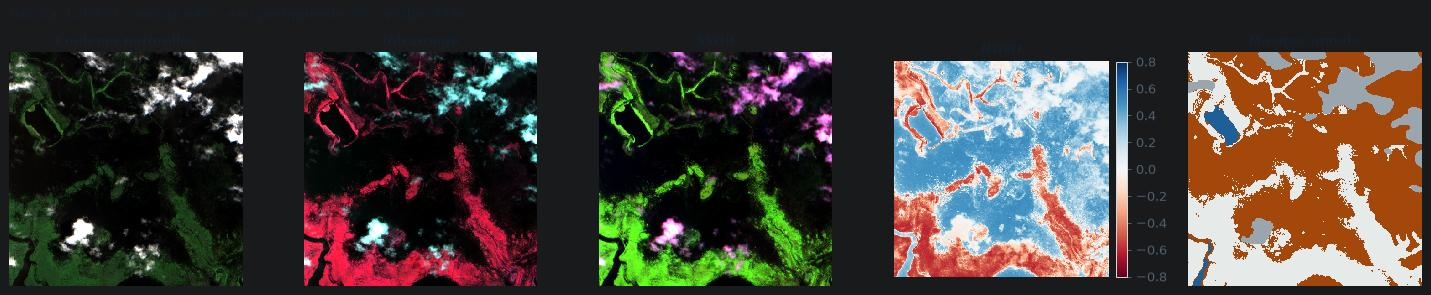

In [8]:
selection = json.loads((S1F / "samples.json").read_text())

def show_flood_tile(tile):
    image = sources.read_band_stack(S1F / "S2Hand" / f"{tile}_S2Hand.tif")
    label = sources.read_band_stack(S1F / "LabelHand" / f"{tile}_LabelHand.tif")[0]
    permanent = sources.read_band_stack(S1F / "JRCWaterHand" / f"{tile}_JRCWaterHand.tif")[0]
    s = stats[tile]
    show_row(
        [natural_color(image), false_color_infrared(image), false_color_swir(image), ndwi(image),
         flood_mask_classes(label, permanent)],
        ["Couleurs naturelles", "Infrarouge", "SWIR", "NDWI", "Masque annoté"],
        cmaps=[None, None, None, "RdBu", MASK_CMAP],
        vranges=[None, None, None, (-0.8, 0.8), (0, 3)],
        suptitle=f"{tile} · inondé {s['flood']:.0%} · eau permanente {s['permanent']:.0%} · visible {s['valid']:.0%}",
    )

for tile in selection["flood"]:
    show_flood_tile(tile)

### Tuiles sans inondation (futures images « normales »)

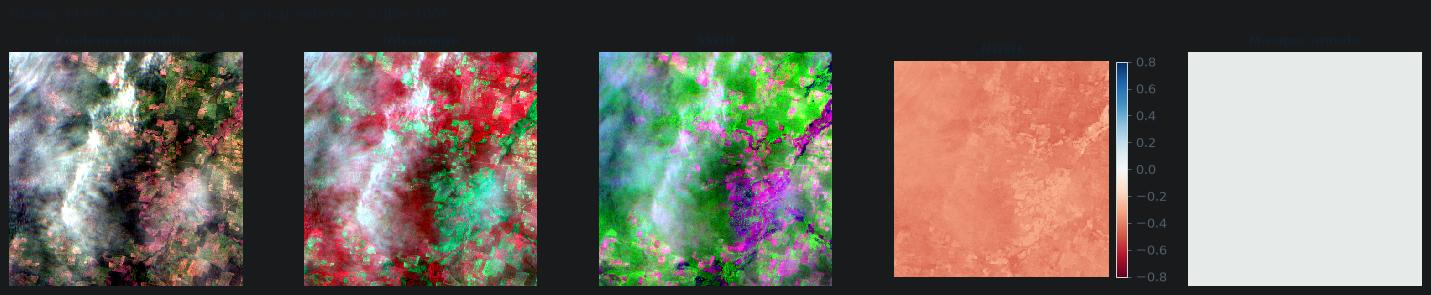

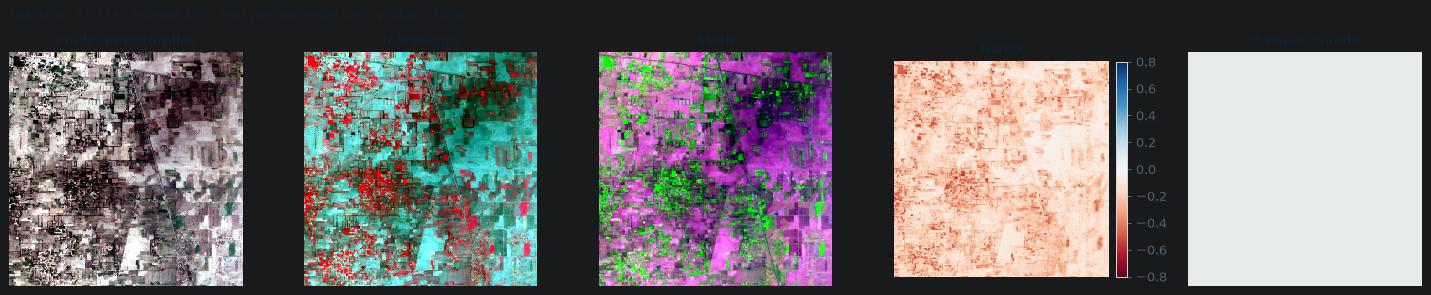

In [9]:
for tile in selection["normal"]:
    show_flood_tile(tile)

### Première approche, sans apprentissage : NDWI > 0

On compte les pixels où NDWI > 0 et on compare à l'eau annotée.
Ce sera la **référence** que les modèles suivants devront battre.

In [ ]:
print(f"{'Tuile':<20} | {'eau annotée':>11} | {'NDWI > 0':>8} | {'accord pixel':>12}")
for tile in selection["flood"] + selection["normal"]:
    image = sources.read_band_stack(S1F / "S2Hand" / f"{tile}_S2Hand.tif")
    label = sources.read_band_stack(S1F / "LabelHand" / f"{tile}_LabelHand.tif")[0]
    visible = label != sources.LABEL_NODATA
    truth = (label == sources.LABEL_WATER)[visible]
    pred = (ndwi(image) > 0)[visible]
    print(f"{tile:<20} | {truth.mean():>11.0%} | {pred.mean():>8.0%} | {(truth == pred).mean():>12.0%}")

## 3. CaBuAr : à quoi ressemble une zone brûlée ?

CaBuAr fournit l'image **avant** et **après** le feu. Le modèle n'aura que l'image après :
la comparaison sert seulement à comprendre la signature du brûlé.

- **NBR** : chute nettement sur le sol brûlé (rouge).
- **dNBR** = NBR avant − NBR après : grand là où ça a brûlé. Utile pour comprendre, pas pour le modèle.

In [ ]:
fire_meta = json.loads((CAB / "samples.json").read_text())

for key, meta in fire_meta.items():
    post = sources.read_band_stack(CAB / f"{key}_post.tif")
    mask = sources.read_band_stack(CAB / f"{key}_mask.tif")[0] > 0
    images, titles, cmaps, ranges = [], [], [], []
    if meta["has_pre_fire"]:
        pre = sources.read_band_stack(CAB / f"{key}_pre.tif")
        images += [natural_color(pre)]; titles += ["Avant · couleurs naturelles"]; cmaps += [None]; ranges += [None]
    images += [natural_color(post), false_color_swir(post), nbr(post), mask]
    titles += ["Après · couleurs naturelles", "Après · SWIR", "Après · NBR", "Masque brûlé"]
    cmaps += [None, None, "RdYlGn", BURN_CMAP]; ranges += [None, None, (-0.6, 0.8), (0, 1)]
    show_row(images, titles, cmaps, ranges, suptitle=f"{key[:8]}… · pli {meta['fold']} · brûlé {meta['burned']:.0%}")

In [ ]:
print(f"{'Tuile':<12} | {'NBR brûlé':>9} | {'NBR non brûlé':>13} | {'dNBR brûlé':>10}")
for key, meta in fire_meta.items():
    post = sources.read_band_stack(CAB / f"{key}_post.tif")
    mask = sources.read_band_stack(CAB / f"{key}_mask.tif")[0] > 0
    n_post = nbr(post)
    dnbr = "—"
    if meta["has_pre_fire"]:
        pre = sources.read_band_stack(CAB / f"{key}_pre.tif")
        dnbr = f"{(nbr(pre) - n_post)[mask].mean():.2f}"
    print(f"{key[:10]+'…':<12} | {n_post[mask].mean():>9.2f} | {n_post[~mask].mean():>13.2f} | {dnbr:>10}")

## 4. L1C contre L2A : le piège de l'harmonisation

Sen1Floods11 est en L1C (réflectance au sommet de l'atmosphère), CaBuAr en L2A (réflectance de surface).
On compare la distribution des mêmes bandes dans les deux sources.
Si elles diffèrent nettement, un modèle pourrait reconnaître **la source** au lieu du phénomène.

In [ ]:
def band_values(paths, names):
    values = {n: [] for n in names}
    for p in paths:
        image = sources.read_band_stack(p)
        bands = get_bands(image, names)
        ok = bands.sum(axis=0) > 0
        for n, b in zip(names, bands):
            values[n].append(b[ok])
    return {n: np.concatenate(v) for n, v in values.items()}

names = ["B02", "B04", "B08", "B12"]
l1c = band_values(sorted((S1F / "S2Hand").glob("*.tif")), names)
l2a = band_values(sorted(CAB.glob("*_post.tif")) + sorted(CAB.glob("*_pre.tif")), names)

fig, axes = plt.subplots(1, len(names), figsize=(13, 2.8))
for ax, n in zip(axes, names):
    bins = np.linspace(0, 0.5, 60)
    ax.hist(l1c[n], bins=bins, density=True, alpha=0.6, color=BRAND, label="Sen1Floods11 · L1C")
    ax.hist(l2a[n], bins=bins, density=True, alpha=0.6, color=ALERT, label="CaBuAr · L2A")
    ax.set_title(n); ax.set_yticks([])
axes[0].legend(fontsize=8); fig.tight_layout(); plt.show()

for n in names:
    print(f"{n} · médiane L1C {np.median(l1c[n]):.3f} · médiane L2A {np.median(l2a[n]):.3f}")

## 5. À retenir

Constats sur cet échantillon (6 tuiles Sen1Floods11, 3 tuiles CaBuAr), reportés dans le carnet de données :

1. **Le seuil d'alerte pèse lourd.** À 1 % de pixels inondés, 61 % des tuiles Sen1Floods11 seraient en alerte ; à 10 %, 20 % ; à 20 %, 10 %. Sen1Floods11 ne contient que des scènes d'inondation : les images normales devront venir d'ailleurs.
2. **L'eau d'inondation est souvent boueuse.** En couleurs naturelles elle paraît marron ; dans la bande B08 (proche infrarouge) elle reste très sombre, d'où sa couleur bleu-cyan dans la composition infrarouge. Les bandes invisibles sont indispensables.
3. **NDWI > 0 est une bonne première référence**, sans apprentissage : 73 à 97 % d'accord par pixel sur les tuiles inondées, 100 % sur les tuiles sèches. Le cas le plus faible (Pakistan, 73 %) sous-estime l'eau : eau très turbide ou peu profonde.
4. **Piège majeur : l'eau a aussi un NBR très bas.** Sur une tuile CaBuAr côtière, l'océan donne un NBR de −0,46, plus bas que la zone brûlée (−0,31). Un modèle basé sur le seul NBR confondrait mer et brûlé : il faudra combiner NBR et indices de l'eau.
5. **L1C et L2A ont des valeurs très différentes**, surtout en SWIR : médiane B12 de 0,05 (L1C, Sen1Floods11) contre 0,23 (L2A, CaBuAr). Une partie vient du niveau de traitement, une partie des paysages (zones tropicales humides contre Californie sèche). Le risque de « reconnaître la source » est réel : l'harmonisation est indispensable.
6. **L'échantillon CaBuAr est peu brûlé** (3 à 10 % de la tuile). Il faudra examiner plus de tuiles pour en trouver de très brûlées, et vérifier le décalage de +1 000 appliqué aux L2A depuis janvier 2022.